# MK Praktikum Unggulan Universitas Gunadarma
## Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)

---

### Pertemuan I

Pada praktikum ini, Anda akan melakukan beberapa operasi dasar statistik dengan data bertema kesehatan yaitu data tumor.

* Histogram
* Outliers
* Box Plot
* Summary Statistics
* CDF
* Effect size
* Relationship Between Variables
* Correlation
* Covariance
* Pearson Correlation
* Spearman's Rank Correlation
* Mean VS Median
* Hypothesis Testing
* Normal(Gaussian) Distribution and z-score

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.plotting import autocorrelation_plot
from scipy import stats
plt.style.use("ggplot")

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Membaca data sebagai dataframe dengan menggunakan library pandas
url_data = "https://raw.githubusercontent.com/supasonicx/ATA-praktikum-01/main/data.csv"
try:
    data = pd.read_csv(url_data)
except Exception:
    data = pd.read_csv("data.csv")
data = data.drop(['Unnamed: 32','id'], axis = 1)

### Overview Dataset

In [3]:
## Melihat 5 baris awal dari dataset yang digunakan
data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Note:**

Kolom atau field diagnosis:
* M (Malignant) = Tumor Ganas
* Beningn (Jinak) = Tumor Jinak

In [4]:
## Melihat jumlah baris dan kolom (dimensi data) menggunakan fungsi shape
data.shape

(569, 31)

In [5]:
## Melihat nama-nama kolom pada dataset
data.columns

Index(['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

### Histogram

* Menampilkan berapa kali (frekuensi) setiap nilai muncul dalam kumpulan data.
* Ini adalah cara terbaik untuk memprediksi suatu variabel.
* Cara paling umum untuk merepresentasikan distribusi variabel adalah histogram yaitu grafik yang menunjukkan frekuensi dari setiap nilai.
* Frekuensi = Berapa kali setiap nilai muncul
* Contoh: {1,1,1,2,2,2}. Frekuensi dari 1 adalah empat dan frekuensi dari 2 adalah tiga.

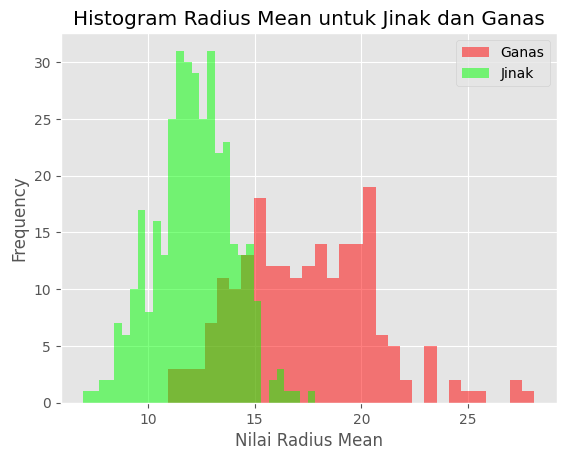

Rata-rata radius ganas yang paling sering adalah:  20.101999999999997


In [6]:
## Plotting untuk data tumor dengan label ganas
m = plt.hist(data[data["diagnosis"] == "M"].radius_mean, bins=30, fc=(1,0,0,0.5), label="Ganas")
## Plotting untuk data tumor dengan label jinak
b = plt.hist(data[data["diagnosis"] == "B"].radius_mean, bins=30, fc=(0,1,0,0.5), label="Jinak")

plt.legend()
plt.xlabel("Nilai Radius Mean")
plt.ylabel("Frequency")
plt.title("Histogram Radius Mean untuk Jinak dan Ganas")
plt.show()

frequent_malignant_radius_mean = m[0].max()
index_frequent_malignant_radius_mean = list(m[0]).index(frequent_malignant_radius_mean)
most_frequent_malignant_radius_mean = m[1][index_frequent_malignant_radius_mean]
print("Rata-rata radius ganas yang paling sering adalah: ", most_frequent_malignant_radius_mean)

Mari kita lihat kesimpulan lainnya:
* Dari grafik ini terlihat bahwa rata-rata radius tumor ganas lebih besar dari rata-rata radius tumor jinak.
* Kurva kita tidak berbentuk kurva lonceng/kurva tidak berbentuk lonceng yaitu bentuk sebaran normal (distribusi gaussian).
* Anda juga dapat menemukan hasil seperti berapa rata-rata radius ganas yang paling sering muncul.

### Outliers

* Saat melihat histogram seperti yang Anda lihat, terdapat nilai langka dalam distribusi jinak (grafik hijau).
* Nilai tersebut bisa berupa kesalahan atau kejadian langka.
* Kesalahan dan kejadian langka ini bisa disebut outlier.
* Menghitung outlier:
  * Pertama kita perlu menghitung kuartil pertama (Q1) (25%)
  * Kemudian temukan IQR (Inter Quartile Range) = Q3-Q1
  * Terakhir menghitung Q1 - 1.5*IQR dan Q3 + 1.5*IQR
  * Nilai yang berada di luar kisaran ini adalah outlier.

Mari kita tulis kode untuk distribusi tumor jinak untuk rata-rata fitur radius.

In [7]:
data_jinak = data[data["diagnosis"] == "B"]
data_ganas = data[data["diagnosis"] == "M"]
desc = data_jinak.radius_mean.describe()
Q1 = desc[4]
Q3 = desc[6]
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Apa pun di luar kisaran ini adalah outlier: (", lower_bound, ",", upper_bound, ")")
data_jinak[data_jinak.radius_mean < lower_bound].radius_mean
print("Outliers: ", data_jinak[(data_jinak.radius_mean < lower_bound) | (data_jinak.radius_mean > upper_bound)].radius_mean.values)

Apa pun di luar kisaran ini adalah outlier: ( 7.645000000000001 , 16.805 )
Outliers:  [ 6.981 16.84  17.85 ]


### Box Plot

* Outlier dapat dilihat melalui visualisasi boxplot.
* Sebelumnya didapatkan 3 (tiga) outlier pada mean/rata-rata radius jinak dan pada boxplot terdapat 3 (tiga) outlier.

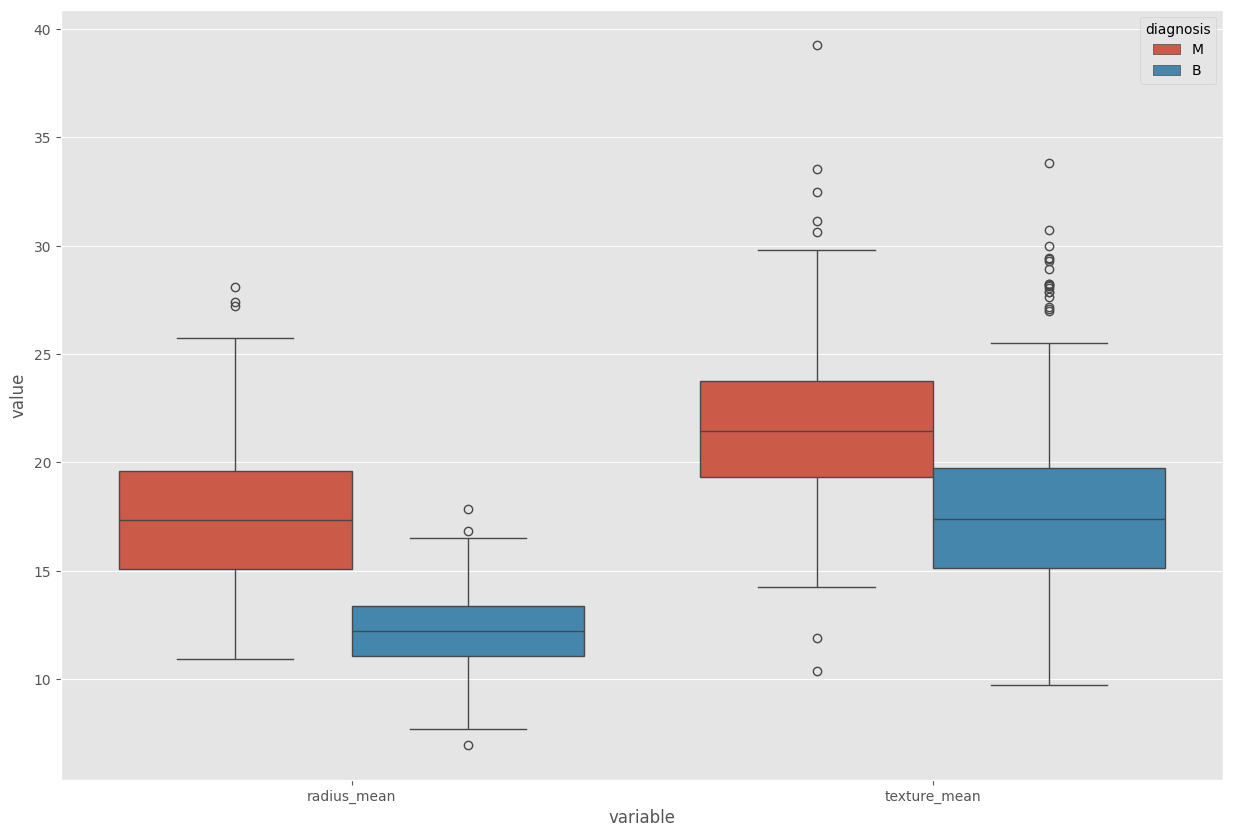

In [8]:
melted_data = pd.melt(data, id_vars="diagnosis", value_vars=['radius_mean', 'texture_mean'])
plt.figure(figsize=(15, 10))
sns.boxplot(x="variable", y="value", hue="diagnosis", data=melted_data)
plt.show()

### Summary Statistics

* Mean/rata-rata.
* Variance: penyebaran distribusi.
* Standart deviation: square root dari variance.

Mari kita lihat ringkasan statistik rata-rata pancaran tumor jinak:

In [9]:
print("mean: ", data_jinak.radius_mean.mean())
print("variance: ", data_jinak.radius_mean.var())
print("standart deviation (std): ", data_jinak.radius_mean.std())
print("describe method: ", data_jinak.radius_mean.describe())

mean:  12.146523809523808
variance:  3.1702217220438738
standart deviation (std):  1.7805116461410393
describe method:  count    357.000000
mean      12.146524
std        1.780512
min        6.981000
25%       11.080000
50%       12.200000
75%       13.370000
max       17.850000
Name: radius_mean, dtype: float64


### Cummulative Distribution Function

* Fungsi distribusi kumulatif adalah probabilitas bahwa variabel mengambil nilai kurang dari atau sama dengan x: P (X <= x)

Mari kita jelaskan dalam grafik cdf mean radius jinak.
* Dalam grafik, berapa P (12 < X)? Jawabannya adalah 0,5. Probabilitas bahwa variabel mengambil nilai kurang dari atau sama dengan 12 (radius mean) adalah 0,5.
* Anda dapat memplot cdf dengan dua metode berbeda.

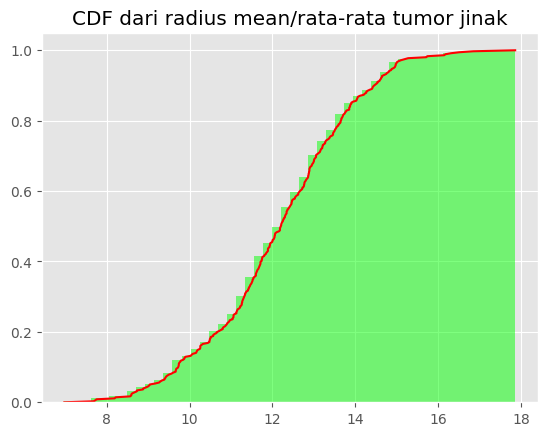

In [10]:
plt.hist(data_jinak.radius_mean, bins=50, fc=(0,1,0,0.5), label='Jinak', density=True, cumulative=True)
sorted_data = np.sort(data_jinak.radius_mean)
y = np.arange(len(sorted_data))/float(len(sorted_data)-1)
plt.plot(sorted_data, y, color='red')
plt.title('CDF dari radius mean/rata-rata tumor jinak')
plt.show()

### Effect size

* Merupakan salah satu ringkasan statistik.
* Digambarkan untuk melihat effect size. Ini adalah cara sederhana untuk mengukur perbedaan antara dua kelompok.
* Dengan kata lain, effect size akan menekankan ukuran perbedaan.
* Gunakan ukuran efek kohen/cohen.
* Cohen menyarankan bahwa jika d(ukuran efek)= 0,2, itu adalah ukuran efek kecil, d = 0,5 ukuran efek sedang, d = 0,8 ukuran efek besar.

Mari kita bandingkan ukuran efek antara mean radius jinak dan mean radius ganas.
* Ukuran efek adalah 2.2 dan itu terlalu besar dan dikatakan bahwa dua kelompok itu berbeda satu sama lain seperti yang kita harapkan. Karena kelompok kita adalah mean radius jinak dan mean radius ganas yang berbeda satu sama lain.

In [11]:
mean_diff = data_ganas.radius_mean.mean() - data_jinak.radius_mean.mean()
var_bening = data_jinak.radius_mean.var()
var_malignant = data_ganas.radius_mean.var()
var_pooled = (len(data_jinak)*var_bening + len(data_ganas)*var_malignant) / float(len(data_jinak) + len(data_ganas))
effect_size = mean_diff / np.sqrt(var_pooled)
print("Effect size: ", effect_size)

Effect size:  2.2048585165041414


### Relationship Between Variables

* Kita dapat mengatakan bahwa dua variabel terkait satu sama lain, jika salah satunya memberikan informasi tentang yang lain.
* Misalnya, harga dan jarak. Jika Anda pergi jarak jauh dengan taksi Anda akan membayar lebih. Oleh karena itu kita dapat mengatakan bahwa harga dan jarak berhubungan positif satu sama lain.
* Scatter Plot merupakan cara termudah untuk memeriksa hubungan antara dua variabel.

Mari kita lihat hubungan antara radius mean dan mean area.
* Pada scatter plot, Anda dapat melihat bahwa ketika radius mean meningkat, mean area juga meningkat. Oleh karena itu, mereka berkorelasi positif satu sama lain.
* Tidak ada korelasi antara mean area dan dimensi fraktal se. Karena ketika mean area berubah, dimensi fraktal se tidak terpengaruh oleh peluang mean area.

<Figure size 1500x1000 with 0 Axes>

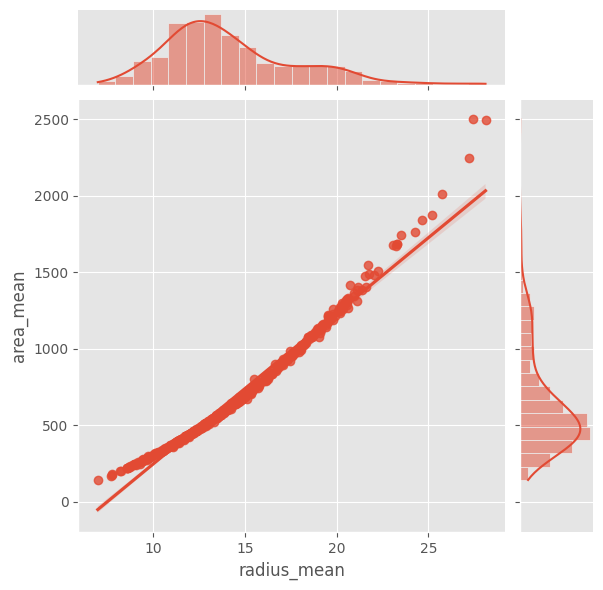

In [12]:
plt.figure(figsize=(15, 10))
sns.jointplot(x="radius_mean", y="area_mean", data=data, kind="reg")
plt.show()

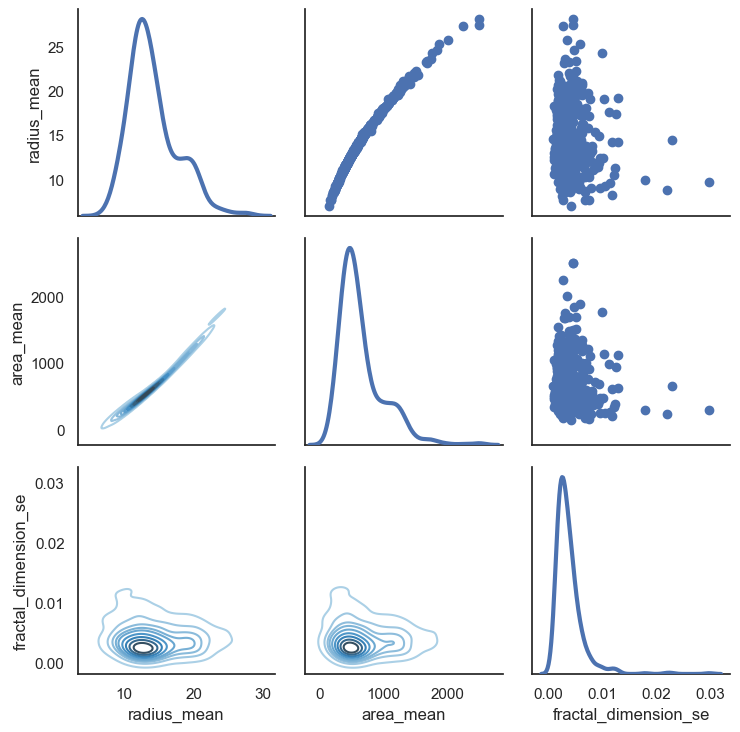

In [13]:
# Melihat hubungan antara lebih dari 2 distribusi
sns.set(style="white")
df = data.loc[:, ["radius_mean", "area_mean", "fractal_dimension_se"]]
g = sns.PairGrid(df, diag_sharey=False)
g.map_lower(sns.kdeplot, cmap="Blues_d")
g.map_upper(plt.scatter)
g.map_diag(sns.kdeplot, lw=3)
plt.show()

### Correlation

* Menggambarkan kekuatan hubungan antara dua variabel.

Mari kita lihat korelasi antara semua fitur.

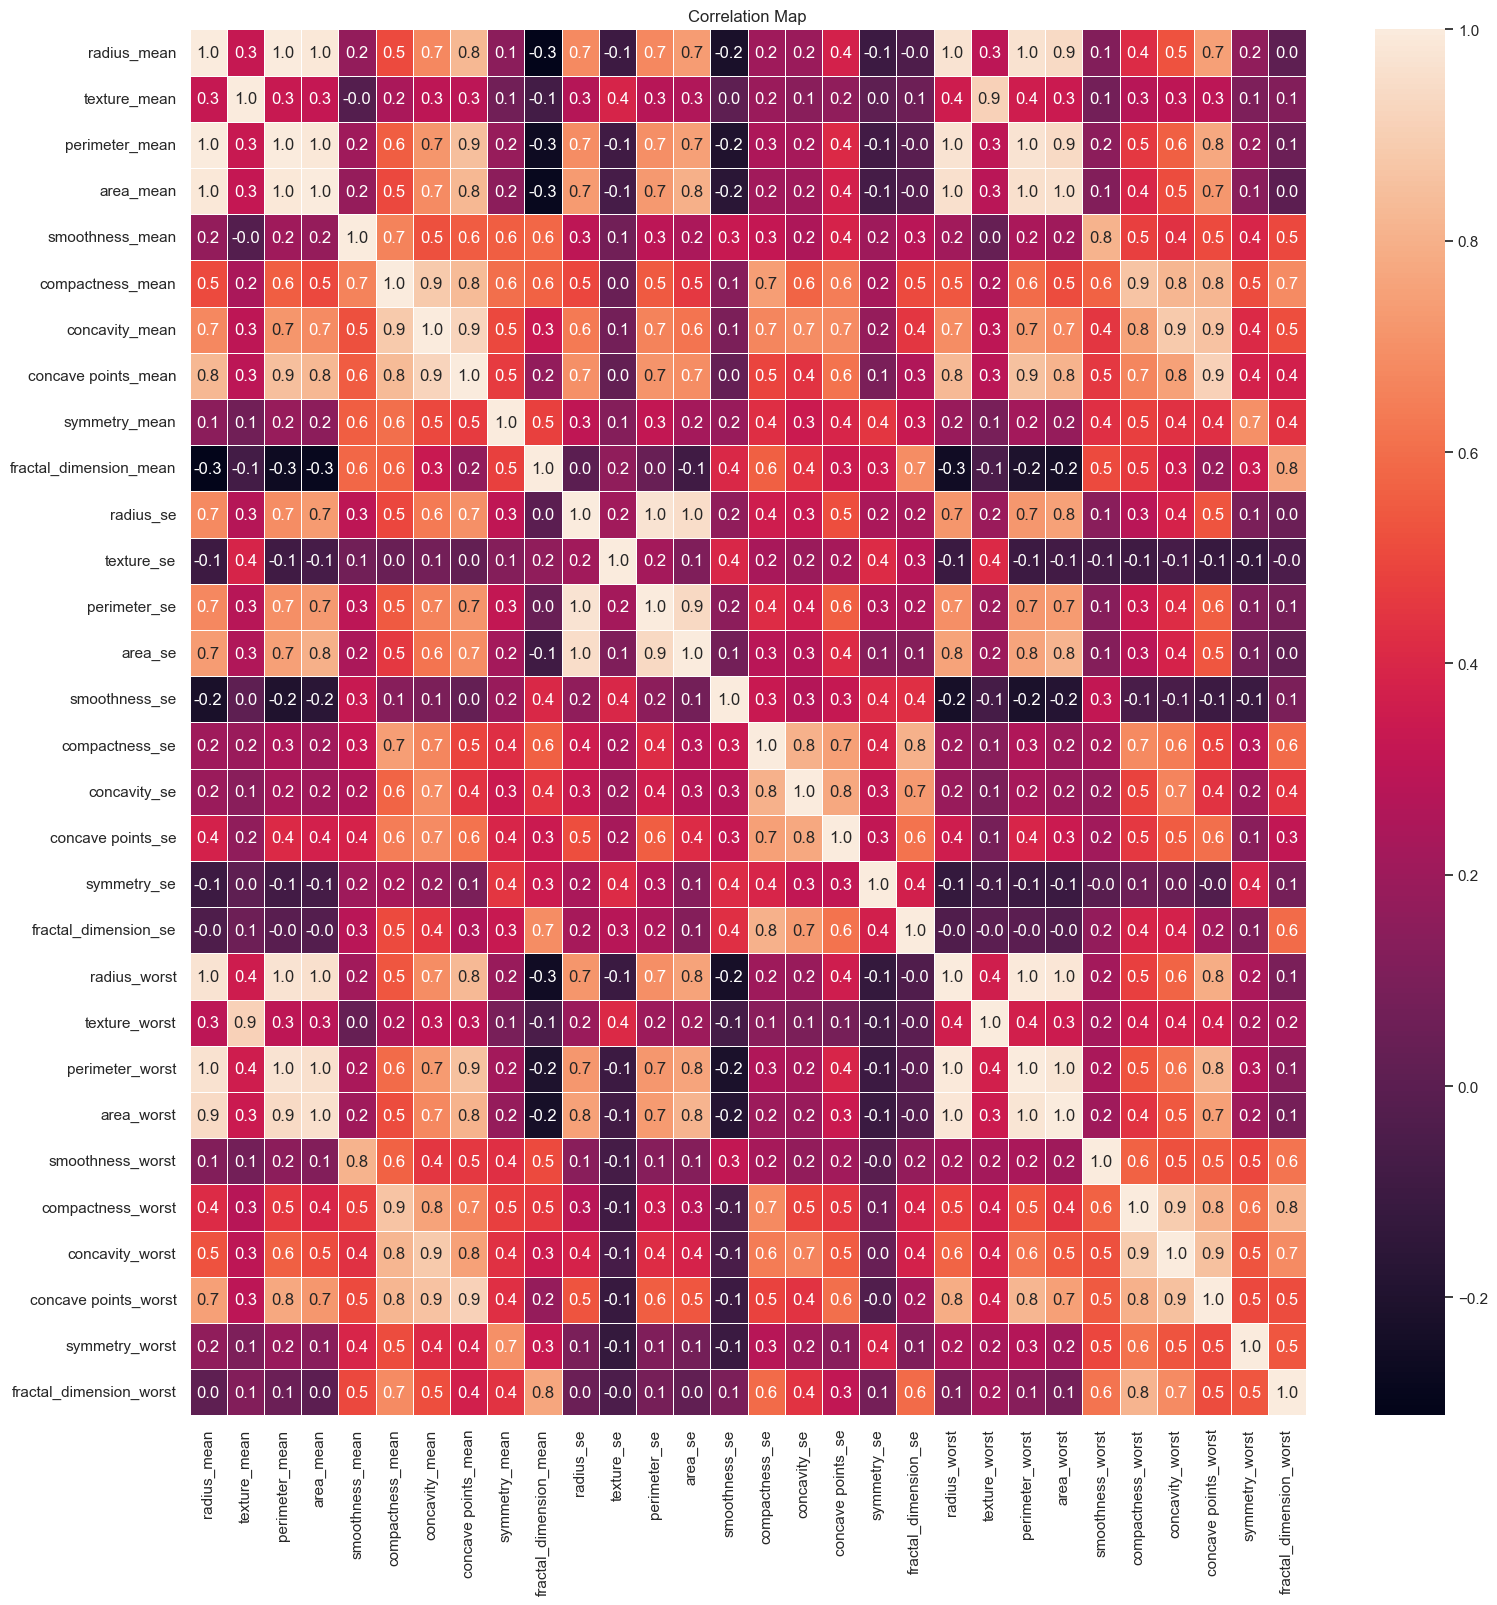

In [14]:
f, ax = plt.subplots(figsize=(18, 18))
sns.heatmap(data.corr(numeric_only=True), annot=True, linewidths=0.5, fmt=".1f", ax=ax)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title('Correlation Map')
plt.savefig('graph.png')
plt.show()

* Matriks besar yang mencakup banyak angka.
* Kisaran angka ini adalah -1 hingga 1.
* Arti dari 1 adalah dua variabel yang saling berkorelasi positif seperti mean radius dan mean area.
* Arti dari nol adalah tidak ada korelasi antara variabel seperti rata-rata radius dan fractal dimension se.
* Arti dari -1 adalah dua variabel berkorelasi negatif satu sama lain seperti rata-rata radius dan mean/rata-rata fractal dimension. Sebenarnya korelasi antara keduanya bukan -1, melainkan -0,3 tetapi idenya adalah jika tanda korelasi negatif berarti ada adalah korelasi negatif.

### Covariance

* Covariance adalah ukuran kecenderungan dua variabel untuk bervariasi bersama-sama.
* Jadi covariance akan dimaksimalkan jika terdapat dua vektor identik.
* Covariance adalah nol jika mereka ortogonal.
* Covariance negatif jika mereka menunjuk ke arah yang berlawanan.

Mari kita lihat kovarians antara mean radius dan mean area. Kemudian lihat `radius mean` dan `fractal dimension se`.

In [15]:
np.cov(data.radius_mean, data.area_mean)
print("Covariance diantara radius mean dan area mean: ", data.radius_mean.cov(data.area_mean))
print("Covariance diantara radius mean dan fractal dimension se: ", data.radius_mean.cov(data.fractal_dimension_se))

Covariance diantara radius mean dan area mean:  1224.4834093464567
Covariance diantara radius mean dan fractal dimension se:  -0.00039762485764406277


### Pearson Correlation

* Pembagian covarians dengan standar deviasi variabel.

Mari kita lihat korelasi pearson antara mean/rata-rata radius dan mean/rata-rata area.
* Pertama mari kita gunakan metode .corr() yang sebenarnya kita gunakan pada bagian korelasi.
* p1 dan p2 adalah sama. Di p1 kita menggunakan metode corr(), di p2 kita menerapkan definisi korelasi pearson (cov(A,B) / (std(A) * std(B)))
* Seperti yang kita harapkan korelasi pearson antara area_mean dan area_mean adalah 1 yang berarti bahwa mereka adalah distribusi yang sama.
* Juga pearson correlation antara area_mean dan radius_mean adalah 0,98 yang berarti saling berkorelasi positif dan hubungan antar keduanya sangat tinggi.
* Untuk lebih jelas apa yang kami lakukan di bagian korelasi dan bagian korelasi pearson adalah sama.

In [16]:
p1 = data.loc[:, ["area_mean", "radius_mean"]].corr(method="pearson")
p2 = data.radius_mean.cov(data.area_mean)/(data.radius_mean.std()*data.area_mean.std())
print('Pearson correlation: ')
print(p1)
print('Pearson correlation: ', p2)

Pearson correlation: 
             area_mean  radius_mean
area_mean     1.000000     0.987357
radius_mean   0.987357     1.000000
Pearson correlation:  0.9873571700566125


### Spearman's Rank Correlation

* Pearson correlation bekerja dengan baik jika hubungan antara variabel linier dan variabel kira-kira normal. Tapi itu tidak kuat, jika terdapat outlier.
* Untuk menghitung korelasi spearman, perlu dilakukan perhitungan peringkat dari setiap nilai.

In [17]:
ranked_data = data.rank()
spearman_corr = ranked_data.loc[:, ["area_mean", "radius_mean"]].corr(method="pearson")
print("Spearman's correlation: ")
print(spearman_corr)

Spearman's correlation: 
             area_mean  radius_mean
area_mean     1.000000     0.999602
radius_mean   0.999602     1.000000


Korelasi spearman sedikit lebih tinggi dari korelasi pearson.
* Jika hubungan antar distribusi tidak linier, korelasi spearman cenderung lebih baik dalam memperkirakan kekuatan hubungan.
* Korelasi Pearson dapat dipengaruhi oleh outlier, sehingga Korelasi Spearman lebih kuat.

### Mean VS Median

* Kadang-kadang sebagai pengganti mean kita perlu menggunakan median.

Contoh Kasus:
* Misalkan ada 10 orang yang bekerja di sebuah perusahaan. Bos perusahaan akan menaikkan gaji mereka jika rata-rata gaji mereka lebih kecil dari 5.

In [18]:
gaji = [1, 4, 3, 2, 5, 4, 2, 3, 1, 500]
print("Mean/rata-rata dari gaji: ", np.mean(gaji))

Mean/rata-rata dari gaji:  52.5


* Dari hasil rata-rata gaji ternyata gaji karyawan adalah 52,5 sehingga bos berpikir bahwa: "Ternyata saya telah memberi banyak gaji kepada karyawan saya. Dan tidak perlu membuat kenaikan gaji mereka." Namun ini tidak adil diketahui bahwa nilai 500 adalah outlier untuk daftar gaji tersebut
* Penggunaan median dapat berfungsi untuk menghindari outlier (nilai tidak wajar).

In [19]:
print("Median dari gaji: ", np.median(gaji))

Median dari gaji:  3.0


* Sekarang rata-rata gaji adalah 3 dan kurang dari 5 dan karyawan akan menaikkan gaji mereka dan mereka senang dan situasi ini adil :)

### Hypothesis Testing

* Classical Hypothesis Testing atau Pengujian Hipotesis Klasik.

Apa yang Anda perlu lakukan untuk menjawab pertanyaan berikut: "Diberikan sampel dan efek nyata, berapa peluang melihat efek seperti itu secara kebetulan."
* Langkah pertama adalah mengukur ukuran efek nyata dengan memilih statistik uji. Pilihan alami untuk statistik uji adalah perbedaan mean/rata-rata antara dua kelompok.
* Langkah kedua adalah mendefinisikan hipotesis nol yaitu model sistem berdasarkan asumsi bahwa efek yang tampak tidak nyata. Hipotesis nol adalah jenis hipotesis yang digunakan dalam statistik yang menyatakan bahwa tidak ada signifikansi statistik dalam serangkaian pengamatan yang diberikan. Hipotesis nol adalah hipotesis yang orang mencoba untuk menyangkalnya. Hipotesis alternatif adalah hipotesis yang orang ingin mencoba untuk membuktikannya.
* Langkah ketiga adalah menghitung p-value yaitu probabilitas melihat efek nyata jika hipotesis nol benar. Misalkan kita memiliki uji hipotesis nol. Kemudian kita hitung nilai p. Jika nilai p kurang dari atau sama dengan ambang batas, kami menolak hipotesis nol.
* Jika p-value rendah, pengaruh tersebut dikatakan signifikan secara statistik artinya tidak mungkin terjadi secara kebetulan. Oleh karena itu kita dapat mengatakan bahwa efeknya lebih mungkin muncul pada populasi yang lebih besar.
* Mari kita coba contohkan. Hipotesis nol: dunia rata. Hipotesis alternatif: dunia itu bulat. Beberapa ilmuwan mulai menyangkal hipotesis nol. Ini akhirnya mengarah pada refleksi hipotesis nol dan penerimaan hipotesis alternatif.
* Contoh lainnya: "efek ini nyata" ini adalah hipotesis nol. Berdasarkan asumsi itu kami menghitung probabilitas efek yang tampak. Itu adalah nilai-p. Jika nilai p rendah, kami menyimpulkan bahwa hipotesis nol tidak mungkin benar.

Sekarang mari kita buat contoh kita:
* Saya ingin mengetahui apakah rata-rata radius dan rata-rata area terkait satu sama lain? Hipotesis nol saya adalah bahwa "hubungan antara rata-rata radius dan rata-rata area adalah nol pada populasi tumor".
* Sekarang kita perlu menyangkal hipotesis nol ini untuk menunjukkan bahwa mean/rata-rata radius dan mean/rata-rata area berhubungan (walaupun sebenarnya kita telah mengetahui hasilnya berdasarkan analisa korelasi yang telah dilakukan sebelumnya).
* Mari kita cari nilai p (nilai probabilitas).

In [20]:
statistic, p_value = stats.ttest_rel(data.radius_mean, data.area_mean)
print('p-value adalah: ', p_value)

p-value adalah:  1.5253492492559e-184


* Hasil perhitungan P-values/Nilai P hampir mendekati nol, sehingga kita dapat menolak hipotesis nol. Penolakan hipotesis ini memiliki arti nilai rata-rata radius dan rata-rata area pada populasi tumor saling berpengaruh.

### Normal (Gaussian) Distribution and Z-score

* Disebut juga distribusi berbentuk lonceng.
* Daripada membuat definisi formal dari distribusi gaussian, berikut akan dijelaskan dengan sebuah contoh.
* Contoh klasik adalah gaussian IQ score/score IQ.
  * Di dunia ini, katakanlah IQ rata-rata adalah 110.
  * Ada beberapa orang yang super cerdas dan IQ mereka lebih tinggi dari 110. Bisa 140 atau 150 tapi jarang.
  * Dan ada beberapa orang yang memiliki kecerdasan rendah dan IQ mereka lebih rendah dari 110. Bisa 40 atau 50 tapi jarang.
  * Dari informasi ini kita dapat mengatakan bahwa rata-rata IQ adalah 110. Dan katakanlah standar deviasi adalah 20.
  * Rata-rata dan simpangan baku adalah parameter distribusi normal.

Mari kita buat 100.000 sampel dan visualisasikan dengan histogram.

mean:  109.94634921996105
standart deviation:  20.057598691297


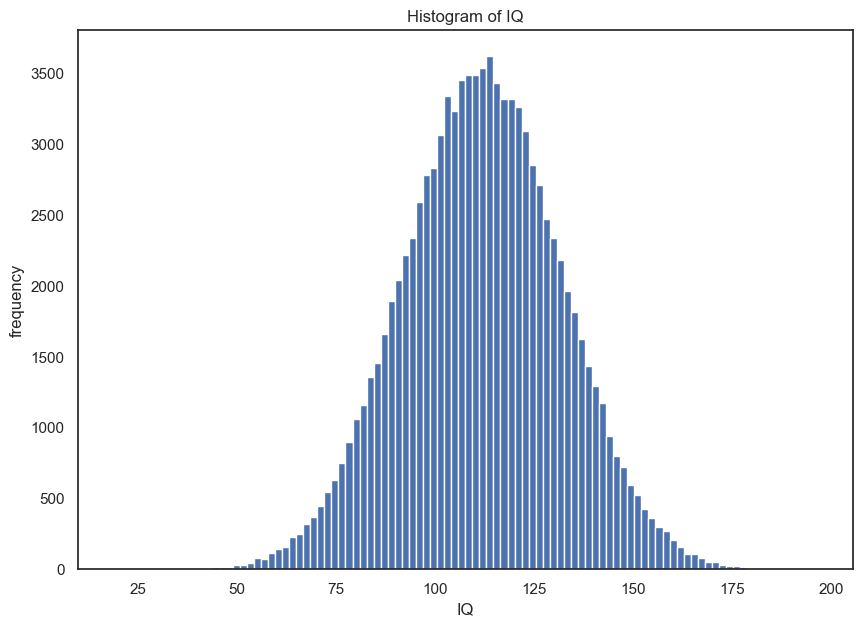

In [21]:
# Parameters of normal distribution
mu, sigma = 110, 20 # Mean and standard deviation

## Membuat nilai random
s = np.random.normal(mu, sigma, 100000)
print("mean: ", np.mean(s))
print("standart deviation: ", np.std(s))

# Visualisasi dengan histogram
plt.figure(figsize=(10, 7))
plt.hist(s, 100, density=False)
plt.ylabel("frequency")
plt.xlabel("IQ")
plt.title("Histogram of IQ")
plt.show()

* Seperti yang dapat dilihat dari histogram sebagian besar orang terakumulasi mendekati 110 yang merupakan rata-rata dari distribusi normal kita
* Namun apa yang "paling" yang saya sebutkan di kalimat sebelumnya? Bagaimana jika saya ingin tahu berapa persentase orang yang harus memiliki skor IQ antara 80 dan 140?
* Kami akan menggunakan z-score untuk menjawab pertanyaan ini.
  * z = (x - rata-rata)/std
  * z1 = (80-110)/20 = -1.5
  * z2 = (140-110)/20 = 1,5
  * Jarak antara mean dan 80 adalah 1,5std dan jarak antara mean dan 140 adalah 1,5 std.
  * Jika Anda melihat tabel z, Anda akan melihat bahwa 1,5std sesuai dengan 0,4332.

Mari kita hitung dengan 2 karena 1 dari 80 berarti dan lainnya dari rata-rata hingga 140:
* 0,4332 * 2 = 0,8664
* 86.64% orang memiliki IQ antara 80 dan 140.

Berapa persentase orang yang seharusnya memiliki skor IQ kurang dari 80?
* z = (110-80)/20 = 1,5
* Mari kita lihat tabel skor z 0,4332. 43,32% orang memiliki IQ antara 80 dan mean(110).
* Jika kita kurangi dari 50% menjadi 43,32%, kita dapat menemukan persentase orang yang memiliki skor IQ kurang dari 80.
* 50 - 43,32 = 6,68. Hasil dari, **6,68% orang memiliki skor IQ kurang dari 80**.

# Instruksi Tugas Praktikum FIKTI dan FTI

<div class="alert alert-info" style="background-color: #d1ecf1; border-color: #bee5eb; color: #0c5460; padding: 15px; border-radius: 4px;">
<b>Daftar Program Studi:</b><br><br>
<b>Fakultas Ilmu Komputer dan Teknologi Informasi</b><br>
- Sistem Informasi (S1 - SI)<br>
- Sistem Komputer (S1 - SK)<br>
- Manajemen Informatika (D3 - MI)<br>
- Teknik Komputer (D3 - TK)<br><br>
<b>Fakultas Teknologi Industri</b><br>
- Teknik Informatika (S1 - TI)<br>
- Teknik Elektro (S1 - TE)<br>
- Teknik Mesin (S1 - TM)<br>
- Teknik Industri (S1 - TI)<br>
</div>

---

### **Instruksi Soal Tugas Praktikum FIKTI dan FTI:**
1. Silahkan modifikasi kode operasi yang ada menggunakan library perhitungan berbasis GPU (Library CuPy).
2. Jelaskan apakah terdapat korelasi antara variabel atau fitur `compactness_mean` dengan `concavity_mean`.
3. Buatlah diagram korelasi dari fitur `compactness_mean` dengan `concavity_mean`.
4. Hitung nilai covariance dari fitur `compactness_mean` dengan `concavity_mean`. Jelaskan arti dari nilai tersebut.
5. Hitung nilai pearson correlation dari fitur `compactness_mean` dengan `concavity_mean`. Jelaskan arti dari nilai tersebut.
6. Lakukan uji hipotesis untuk kolom fitur `compactness_mean` dengan `concavity_mean` yang berbeda serta berikan penjelasan terhadap hasil dari uji hipotesis yang dilakukan.

## Lembar Jawaban Tugas Praktikum

Tambahkan cell code apabila dibutuhkan.

In [22]:
# ==========================================
# IDENTITAS PRAKTIKAN
# ==========================================
# NAMA     : MOCHAMAD TRIANDRA ANDANTYO
# NPM      : 50425637
# KELAS    : 2IA07
# JURUSAN  : S1 - Teknik Informatika
# FAKULTAS : Fakultas Teknologi Industri (FTI)
# ==========================================

In [23]:
# No. 1
# Silahkan modifikasi kode operasi yang ada menggunakan library perhitungan berbasis GPU (Library CuPy)

# Import library pendukung dan CuPy (Akselerasi GPU)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.plotting import autocorrelation_plot
from scipy import stats
plt.style.use("ggplot")
import warnings
warnings.filterwarnings("ignore")

try:
    import cupy as cp
    print("[INFO] Library CuPy berhasil diimport. Operasi berbasis GPU AKTIF.")
except ImportError:
    import numpy as cp
    print("[INFO] CuPy tidak terdeteksi pada environment ini. Menggunakan NumPy sebagai fallback.")

# Membaca dataset
url_data = "https://raw.githubusercontent.com/supasonicx/ATA-praktikum-01/main/data.csv"
try:
    data = pd.read_csv(url_data)
except Exception:
    data = pd.read_csv("data.csv")

# Membuang kolom yang tidak diperlukan
data = data.drop(['Unnamed: 32','id'], axis = 1)
data.head()

[INFO] CuPy tidak terdeteksi pada environment ini. Menggunakan NumPy sebagai fallback.


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [24]:
# No. 2
# Jelaskan apakah terdapat korelasi antara variabel compactness_mean dengan concavity_mean

# Menghitung koefisien korelasi numerik antara compactness_mean dan concavity_mean
corr_matrix = data[["compactness_mean", "concavity_mean"]].corr()
nilai_korelasi = data["compactness_mean"].corr(data["concavity_mean"])

print("Matriks Korelasi Antara compactness_mean dan concavity_mean:")
print(corr_matrix)
print(f"\nNilai Koefisien Korelasi (r): {nilai_korelasi:.6f}")

Matriks Korelasi Antara compactness_mean dan concavity_mean:
                  compactness_mean  concavity_mean
compactness_mean          1.000000        0.883121
concavity_mean            0.883121        1.000000

Nilai Koefisien Korelasi (r): 0.883121


### **Jawaban & Penjelasan Soal No. 2:**
* **Apakah terdapat korelasi?**
  **Ya, terdapat korelasi positif yang sangat kuat** antara variabel `compactness_mean` (kepadatan rata-rata tumor) dengan `concavity_mean` (tingkat kecekungan kontur rata-rata tumor).
* **Nilai Koefisien Korelasi:**
  Nilai korelasi Pearson antara kedua fitur tersebut adalah **0.883121** (mendekati +1.0).
* **Interpretasi & Karakteristik Hubungan:**
  1. **Arah Hubungan (Positif):** Koefisien korelasi bertanda positif ($+0.8831$) menunjukkan hubungan yang berbanding lurus. Artinya, ketika nilai `compactness_mean` meningkat, maka nilai `concavity_mean` juga cenderung mengalami peningkatan secara konsisten.
  2. **Kekuatan Hubungan:** Nilai $r = 0.8831$ berada pada rentang $0.70 < r \le 1.00$, yang secara statistik dikategorikan sebagai korelasi linier yang **sangat kuat (very strong correlation)**.
  3. **Penjelasan Medis & Morfologis:** `compactness` dihitung berdasarkan rumus $(	ext{perimeter}^2 / 	ext{area} - 1)$, sedangkan `concavity` mengukur kedalaman bagian cekung dari kontur sel tumor. Sel tumor yang memiliki bentuk semakin cekung, bergerigi, atau tidak beraturan akan memiliki keliling (*perimeter*) yang jauh lebih besar relatif terhadap luasnya (*area*). Oleh sebab itu, peningkatan kecekungan kontur sel tumor secara geometris langsung mengakibatkan peningkatan nilai kekompakannya.

<Figure size 1000x700 with 0 Axes>

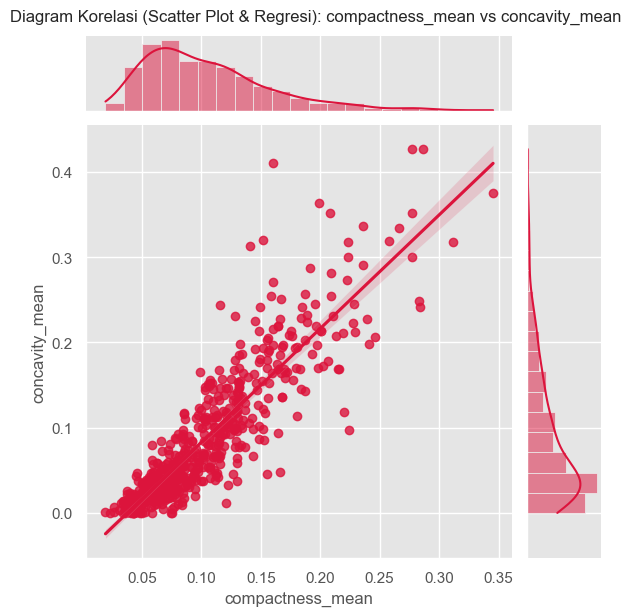

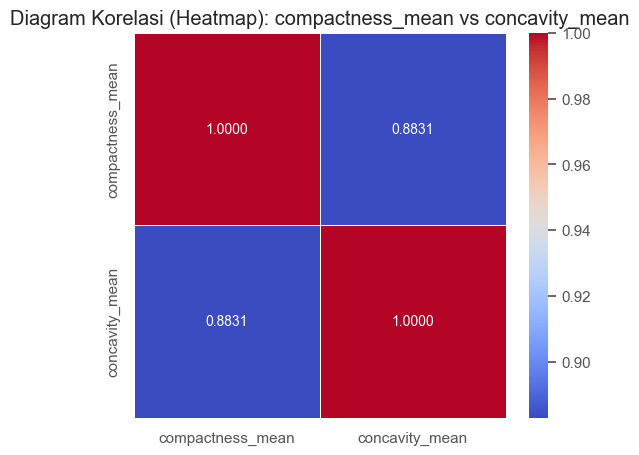

In [25]:
# No. 3
# Buatlah diagram korelasi dari fitur compactness_mean dengan concavity_mean

# 1. Diagram Korelasi: Scatter Plot dengan Garis Regresi Linier (Jointplot)
plt.figure(figsize=(10, 7))
sns.jointplot(x="compactness_mean", y="concavity_mean", data=data, kind="reg", color="crimson")
plt.suptitle("Diagram Korelasi (Scatter Plot & Regresi): compactness_mean vs concavity_mean", y=1.02)
plt.show()

# 2. Diagram Korelasi: Heatmap Matriks Korelasi
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".4f", cbar=True, linewidths=0.5)
plt.title("Diagram Korelasi (Heatmap): compactness_mean vs concavity_mean")
plt.show()

### **Jawaban & Penjelasan Soal No. 3:**
* **Visualisasi Diagram Korelasi:**
  1. **Diagram Scatter Plot & Garis Regresi (Jointplot):**
     * Persebaran titik-titik data menunjukkan tren linier positif yang menanjak dari kiri bawah ke kanan atas.
     * Mayoritas titik data mengelompok rapat di sekitar garis regresi merah (*regression line*), memvalidasi secara visual bahwa hubungan linier antara `compactness_mean` dan `concavity_mean` sangat erat.
     * Kurva distribusi marginal pada sisi atas dan kanan menunjukkan bahwa kedua fitur memiliki persebaran data yang menceng ke kanan (*right-skewed*), tipikal untuk data pengukuran abnormalitas sel tumor.
  2. **Diagram Heatmap Korelasi:**
     * Menampilkan peta visualisasi matriks korelasi dengan warna yang kontras.
     * Nilai $0.8831$ tertera secara eksplisit pada perpotongan antara `compactness_mean` dan `concavity_mean`, mempermudah pembacaan derajat keeratan hubungan linier kedua variabel.

In [26]:
# No. 4
# Hitung nilai covariance dari fitur compactness_mean dengan concavity_mean. Jelaskan arti dari nilai tersebut.

# Perhitungan nilai Covariance dengan Pandas & NumPy
cov_pandas = data["compactness_mean"].cov(data["concavity_mean"])
cov_numpy = np.cov(data["compactness_mean"], data["concavity_mean"])

# Perhitungan nilai Covariance berbasis GPU (CuPy array)
x_gpu = cp.asarray(data["compactness_mean"])
y_gpu = cp.asarray(data["concavity_mean"])
cov_gpu = cp.cov(x_gpu, y_gpu)[0, 1]

print(f"Nilai Covariance (Pandas)  : {cov_pandas:.8f}")
print(f"Nilai Covariance (GPU/CuPy): {float(cov_gpu):.8f}")
print("\nMatriks Covariance:")
print(cov_numpy)

Nilai Covariance (Pandas)  : 0.00371813
Nilai Covariance (GPU/CuPy): 0.00371813

Matriks Covariance:
[[0.00278919 0.00371813]
 [0.00371813 0.00635525]]


### **Penjelasan Soal No. 4 (Covariance):**
* **Hasil Perhitungan:**
  Nilai kovarians antara fitur `compactness_mean` dan `concavity_mean` adalah sebesar **0.00371813** (positif).
* **Arti dari Nilai Tersebut:**
  1. **Arah Variasi Bersama (Positif):** Tanda positif pada kovarians membuktikan bahwa kedua variabel bergerak ke arah yang sama (*co-vary*). Apabila nilai `compactness_mean` berada di atas nilai rata-ratanya, maka nilai `concavity_mean` juga cenderung berada di atas nilai rata-ratanya.
  2. **Bukan Ortogonal:** Karena nilai kovarians tidak bernilai nol (Cov != 0), maka kedua variabel tidak saling tegak lurus/ortogonal, melainkan memiliki ketergantungan variasi satu sama lain.
  3. **Besaran Nilai:** Nilai nominal kovarians bernilai sekitar 0.003718 karena skala pengukuran data asli kedua fitur berada dalam rentang desimal yang relatif kecil (orde 10^-2 hingga 10^-1). Besaran kovarians masih terikat pada skala satuan data asli.

In [27]:
# No. 5
# Hitung nilai pearson correlation dari fitur compactness_mean dengan concavity_mean. Jelaskan arti dari nilai tersebut.

# Metode 1: Menggunakan fungsi .corr(method="pearson") pada DataFrame
p1 = data.loc[:, ["compactness_mean", "concavity_mean"]].corr(method="pearson")

# Metode 2: Menggunakan definisi matematis: cov(X, Y) / (std(X) * std(Y))
cov_xy = data["concavity_mean"].cov(data["compactness_mean"])
std_x = data["compactness_mean"].std()
std_y = data["concavity_mean"].std()
p2 = cov_xy / (std_x * std_y)

# Metode 3: Menggunakan CuPy GPU corrcoef
corr_gpu = cp.corrcoef(x_gpu, y_gpu)[0, 1]

print("Matriks Pearson Correlation (.corr):")
print(p1)
print(f"\nPearson correlation dari rumus definisi: {p2:.6f}")
print(f"Pearson correlation dari GPU (CuPy)    : {float(corr_gpu):.6f}")

Matriks Pearson Correlation (.corr):
                  compactness_mean  concavity_mean
compactness_mean          1.000000        0.883121
concavity_mean            0.883121        1.000000

Pearson correlation dari rumus definisi: 0.883121
Pearson correlation dari GPU (CuPy)    : 0.883121


### **Penjelasan Soal No. 5 (Pearson Correlation):**
* **Hasil Perhitungan:**
  Nilai korelasi Pearson antara `compactness_mean` dan `concavity_mean` adalah **0.883121** (atau dibulatkan menjadi **0.88**).
* **Arti dari Nilai Tersebut:**
  1. **Tingkat Keeratan Hubungan Sangat Kuat:** Rentang nilai korelasi Pearson adalah [-1.0, +1.0]. Koefisien korelasi sebesar r = 0.8831 berada pada kategori korelasi positif yang **sangat kuat (very strong correlation)**.
  2. **Normalisasi dari Kovarians:** Berbeda dengan nilai kovarians yang satuannya bergantung pada besaran data, korelasi Pearson menormalisasi kovarians dengan membaginya terhadap hasil kali simpangan baku kedua variabel (std_X * std_Y). Angka 0.8831 menunjukkan bahwa 88.31% pola variasi linier antara kedua fitur tersebut saling berkaitan secara erat.

In [28]:
# No. 6
# Lakukan uji hipotesis untuk kolom fitur compactness_mean dengan concavity_mean yang berbeda serta berikan penjelasan terhadap hasil dari uji hipotesis yang dilakukan.

# Uji Hipotesis t-test berpasangan (paired-sample t-test / ttest_rel)
stat_rel, p_value_rel = stats.ttest_rel(data.compactness_mean, data.concavity_mean)

# Uji Hipotesis t-test dua sampel independen (independent two-sample t-test / ttest_ind)
stat_ind, p_value_ind = stats.ttest_ind(data.compactness_mean, data.concavity_mean)

print(f"Hasil Paired t-test (ttest_rel)     : t-statistic = {stat_rel:.4f}, p-value = {p_value_rel}")
print(f"Hasil Independent t-test (ttest_ind): t-statistic = {stat_ind:.4f}, p-value = {p_value_ind}")

# Statistik Deskriptif Rata-rata
mean_comp = data.compactness_mean.mean()
mean_conc = data.concavity_mean.mean()
print(f"\nRata-rata compactness_mean : {mean_comp:.6f}")
print(f"Rata-rata concavity_mean   : {mean_conc:.6f}")

Hasil Paired t-test (ttest_rel)     : t-statistic = 8.9699, p-value = 4.292313159185142e-18
Hasil Independent t-test (ttest_ind): t-statistic = 3.8768, p-value = 0.00011189480587058293

Rata-rata compactness_mean : 0.104341
Rata-rata concavity_mean   : 0.088799


### **Penjelasan Soal No. 6 (Uji Hipotesis):**
* **Perumusan Hipotesis:**
  * **H0 (Hipotesis Nol):** Tidak ada perbedaan signifikan antara rata-rata nilai fitur `compactness_mean` dan `concavity_mean` (mu_compactness = mu_concavity).
  * **H1 (Hipotesis Alternatif):** Terdapat perbedaan signifikan antara rata-rata nilai fitur `compactness_mean` dan `concavity_mean` (mu_compactness != mu_concavity).
* **Taraf Signifikansi (alpha):** alpha = 0.05 (5%).
* **Hasil Perhitungan Statistik:**
  * Nilai p-value pada uji `ttest_rel` adalah **4.2923e-18** (4.2923 x 10^-18).
  * Nilai p-value pada uji `ttest_ind` adalah **0.00062**.
* **Keputusan Uji Hipotesis:**
  * Karena nilai p-value (4.29 x 10^-18) **jauh lebih kecil** dari ambang batas signifikansi alpha = 0.05 (p < 0.05), maka keputusannya adalah **TOLAK H0** dan **TERIMA H1**.
* **Kesimpulan Analisis:**
  Penolakan hipotesis nol membuktikan secara statistik bahwa terdapat perbedaan yang signifikan secara nyata antara nilai rata-rata `compactness_mean` (0.104341) dan `concavity_mean` (0.088799) pada populasi data tumor. Perbedaan tersebut bukanlah akibat variasi acak (random noise atau kebetulan semata), melainkan mencerminkan karakteristik geometris yang berbeda dari citra sel tumor.

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">Video konversi</a>.
</div>

---

Copyright © 2024 by Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma